## Importing libraries and the files

In [1]:
# libraries
from pathlib import Path
import pandas as pd

# paths and files
project_root = Path.cwd().parent
data_folder = project_root / "documents" / "processed"
document_paths = sorted(data_folder.glob("*.txt"))

# Check
document_paths = sorted(data_folder.glob("*.txt"))

## Loading the documents (the processing was performed in /transformer/DataProcessing.ipynb)

In [2]:
documents = []
filenames = []

for path in document_paths:
    # Read text
    text = path.read_text(encoding="utf-8")
    # Store text and associated filename
    documents.append(text)
    filenames.append(path.name)

print("Documents loaded:", len(documents))
print("First document:", filenames[0])
print("Words in first document:", len(documents[0].split()))

Documents loaded: 33
First document: 32624-pdf.txt
Words in first document: 174501


## Vector Representation

In [3]:
# Importing the Bag-of-Words vectorizer
from sklearn.feature_extraction.text import CountVectorizer

In [4]:
# defining vectorizer
vectorizer = CountVectorizer(
    lowercase=True,       # Convert all words to lowercase
    stop_words="english",  # Remove common English stop words
    min_df=2               # Keep words appearing in at least 2 documents
)

In [5]:
# Learn the vocabulary and transform documents into vectors
X_count = vectorizer.fit_transform(documents)

In [6]:
# Retrieve the vocabulary
vocabulary = vectorizer.get_feature_names_out()

In [7]:
# Inspect 
print("Number of documents:", X_count.shape[0])
print("Number of features:", X_count.shape[1])
print("First 20 vocabulary terms:", vocabulary[:20])

Number of documents: 33
Number of features: 24006
First 20 vocabulary terms: ['000' '001' '054' '06' '063' '10' '100' '1000' '101' '1014' '102' '1020'
 '103' '104' '1042' '1045' '1048' '105' '1050' '1057']


## Inspecting the document - term Matrix

In [8]:
# import numpy
import numpy as np

In [9]:
# count of words in each doc
word_frequencies = np.asarray(X_count.sum(axis=0)).ravel()

In [10]:
# Turning vocabulary and frequencies into a DataFrame
frequency_df = pd.DataFrame({
    "word": vocabulary,
    "frequency": word_frequencies
})

In [11]:
# Sort words based on frequency
frequency_df = frequency_df.sort_values(
    by="frequency",
    ascending=False
)

In [12]:
# Display the 30 most frequent words
display(frequency_df.head(30))

,word,frequency
21830,time,3672
10550,great,3530
18814,roman,3041
16127,people,2876
4982,city,2848
14138,men,2714
18832,rome,2561
23369,war,2459
12820,king,2334
23908,years,1910


Frequency does not mean informative. A word that appears a lot can be not meaningful at all for our goal.

## Document Frequency

In [13]:
# Count how many documents contain each term
document_frequencies = np.asarray(
    (X_count > 0).sum(axis=0)
).ravel()

# Create a table containing both frequency measurements
word_analysis = pd.DataFrame({
    "word": vocabulary,
    "total_frequency": word_frequencies,
    "document_frequency": document_frequencies
})

# Calculate the percentage of documents containing each word
word_analysis["document_percentage"] = (
    word_analysis["document_frequency"]
    / X_count.shape[0]
    * 100
)

# Examining most frequent terms
display(
    word_analysis.sort_values(
        "total_frequency",
        ascending=False
    ).head(30)
)

,word,total_frequency,document_frequency,document_percentage
21830,time,3672,31,93.939394
10550,great,3530,32,96.969697
18814,roman,3041,27,81.818182
16127,people,2876,30,90.909091
4982,city,2848,28,84.848485
14138,men,2714,31,93.939394
18832,rome,2561,26,78.787879
23369,war,2459,29,87.878788
12820,king,2334,29,87.878788
23908,years,1910,29,87.878788


## TF-IDF Vectorizer

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [15]:
# definition
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    min_df=2,
    max_df=0.90,
    norm="l2"
)

In [16]:
# Learn the vocabulary and transform the documents
X_tfidf = tfidf_vectorizer.fit_transform(documents)

# Display the dimensions of both representations
print("Bag of Words:", X_count.shape)
print("TF-IDF:", X_tfidf.shape)

Bag of Words: (33, 24006)
TF-IDF: (33, 23955)


## First Model Training

In [17]:
from sklearn.cluster import KMeans

In [18]:
# initial number of clusters
k=3

In [19]:
# inititalizing K-Means
kmeans = KMeans(
    n_clusters=k,
    init="k-means++",
    n_init=20,
    random_state=42
)

In [20]:
# fitting k-means to TF-IDF vectors
cluster_labels = kmeans.fit_predict(X_tfidf)

In [21]:
# Display the assigned cluster for each document
cluster_df = pd.DataFrame({
    "document": filenames,
    "cluster": cluster_labels
})

display(cluster_df)

,document,cluster
0,32624-pdf.txt,1
1,Alexander the Great by Jacob Abbott | Project ...,0
2,Ancient China Simplified by Edward Harper Park...,0
3,Ancient Rome: The Lives of Great Men by Mary A...,0
4,pg1.txt,1
5,pg15663.txt,1
6,pg18041.txt,1
7,pg19725.txt,1
8,pg20110.txt,1
9,pg2131.txt,1


#### Inspecting the clusters

In [22]:
# Count the number of documents assigned to each cluster
cluster_sizes = cluster_df["cluster"].value_counts().sort_index()

print("Documents per cluster:")
display(cluster_sizes)

# Display the K-means objective value (SSE / inertia)
print("Inertia:", kmeans.inertia_)

Documents per cluster:


cluster
0     3
1    26
2     4
Name: count, dtype: int64

Inertia: 23.48195826697903


In [23]:
# Iterate through each cluster
for cluster_id in sorted(cluster_df["cluster"].unique()):

    # Select documents assigned to this cluster
    members = cluster_df[
        cluster_df["cluster"] == cluster_id
    ]

    # Display cluster information
    print(f"\n{'=' * 50}")
    print(f"CLUSTER {cluster_id}")
    print(f"Documents: {len(members)}")
    print("=" * 50)

    # Display the filenames belonging to the cluster
    for filename in members["document"]:
        print(filename)


CLUSTER 0
Documents: 3
Alexander the Great by Jacob Abbott | Project Gutenberg.txt
Ancient China Simplified by Edward Harper Parker | Project Gutenberg.txt
Ancient Rome: The Lives of Great Men by Mary Agnes Hamilton | Project Gutenberg.txt

CLUSTER 1
Documents: 26
32624-pdf.txt
pg1.txt
pg15663.txt
pg18041.txt
pg19725.txt
pg20110.txt
pg2131.txt
pg23495.txt
pg25080.txt
pg25731.txt
pg26880.txt
pg30809.txt
pg35791.txt
pg37756.txt
pg42033.txt
pg46924.txt
pg53083.txt
pg54550.txt
pg6151.txt
pg6152.txt
pg6153.txt
pg6559.txt
pg66663.txt
pg6989.txt
pg72031.txt
pg72216.txt

CLUSTER 2
Documents: 4
pg59270.txt
pg64460.txt
pg68741.txt
pg69646.txt


Cluster 1 is extremely broad. It contains 26 books, meaning K-means hasn't meaningfully separated most of the historical collection at \(k=3\).

Cluster 2 remains a mystery. We have to identify the four books before concluding why they were grouped together.

This suggests the algorithm is detecting something besides historical subject, potentially shared webpage vocabulary, document structure, or the characteristics of these short summaries.

In [24]:
# Retrieve the vocabulary from TF-IDF vectorizer
feature_names = tfidf_vectorizer.get_feature_names_out()

# retrieve the centroid of Cluster 2
centroid = kmeans.cluster_centers_[2]

# Find  indices of the 15 highest-weighted terms
top_indices = centroid.argsort()[-15:][::-1]

# Display most important terms
print("Top 15 terms in Cluster 2:\n")

for index in top_indices:
    print(
        feature_names[index],
        round(centroid[index], 4)
    )

Top 15 terms in Cluster 2:

armenians 0.3299
armenian 0.2856
armenia 0.1602
turkish 0.1584
sultan 0.1342
novel 0.129
turks 0.1244
life 0.1143
turkey 0.1082
roman 0.1063
kurds 0.0859
christian 0.0853
christians 0.0832
church 0.0708
novels 0.0698


## Comparing different values of K

In [25]:
from sklearn.metrics import silhouette_score

# Store experimental results
experiments = []

# Experiment with different numbers of clusters
for k in range(2, 13):

    # Initialize K-means using same settings as before
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        random_state=42
    )

    # Cluster TF-IDF document vectors
    labels = model.fit_predict(X_tfidf)

    # Calculate the silhouette score using cosine distance
    silhouette = silhouette_score(
        X_tfidf,
        labels,
        metric="cosine"
    )

    # Record results
    experiments.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette
    })

# Convert results into DF
experiments_df = pd.DataFrame(experiments)

display(experiments_df)

,k,inertia,silhouette
0,2,25.271163,0.176360
1,3,23.481958,0.120362
2,4,21.372760,0.150601
3,5,20.123553,0.178421
4,6,18.704164,0.184132
5,7,17.776066,0.175833
6,8,16.667722,0.194289
7,9,15.603124,0.202326
8,10,14.434399,0.215738
9,11,13.510780,0.225908


Cosine-distance silhouette score, higher is generally better.

**1**: Inertia decreases from 25.27 to 12.54. This was expected because increasing the number of centroids allows K-means to fit the documents closer. A smaller inertia though, does not automatically indicate better clustering.

**2**: The highest silhouette score sits at \(k=12\). The score of 0.228 shows relatively weak separation between the resulting clusters.

**3**: We cannot conclude that \(k=12\) is the optimal yet. With 33 documents and 12 clusters, we're averaging only 2.75 documents per cluster. Some groups might contain just one document.

## Inspecting the k=12 candidate

In [26]:
model_12 = KMeans(
    n_clusters=12,
    init="k-means++",
    n_init=20,
    random_state=42
)

# Fit the model to TF-IDF vectors
labels_12 = model_12.fit_predict(X_tfidf)

# Associating each document with its assigned cluster
clusters_12 = pd.DataFrame({
    "document": filenames,
    "cluster": labels_12
})

# Examining the number of documents in each cluster
cluster_sizes_12 = (
    clusters_12["cluster"]
    .value_counts()
    .sort_index()
)

display(cluster_sizes_12)

cluster
0     1
1     5
2     3
3     6
4     4
5     5
6     3
7     1
8     1
9     2
10    1
11    1
Name: count, dtype: int64

**Five clusters contain only one document**

\(k=12\) may be producing a fragmented partition for the objective of discovering meaningful historical groups.

## Compare cluster sizes for different values of K

In [27]:
candidate_k = [5, 6, 10]
candidate_models = {}

for k in candidate_k:

    # Fit K-means 
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        random_state=42
    )

    labels = model.fit_predict(X_tfidf)

    # Saving model and document assignments
    candidate_models[k] = {
        "model": model,
        "labels": labels
    }

    # Count documents assigned to each cluster
    cluster_sizes = pd.Series(labels).value_counts().sort_index()

    print(f"\n{'=' * 35}")
    print(f"k = {k}")
    print(f"{'=' * 35}")

    print(cluster_sizes.to_string())

    print("Singleton clusters:", (cluster_sizes == 1).sum())


k = 5
0    12
1     3
2     8
3     7
4     3
Singleton clusters: 0

k = 6
0    8
1    3
2    8
3    5
4    3
5    6
Singleton clusters: 0

k = 10
0    3
1    6
2    7
3    3
4    5
5    2
6    2
7    1
8    1
9    3
Singleton clusters: 2


\(k=6\) can be a reasonable candidate. It produces reasonably distributed clusters without singletons and slightly improves the silhouette score compared with \(k=5\). The deciding factor is historical coherence.

## Historical Meaning

#### K=6 first

In [28]:
k = 6

model = candidate_models[k]["model"]
labels = candidate_models[k]["labels"]

# Retrieve the TF-IDF vocab
feature_names = tfidf_vectorizer.get_feature_names_out()

# Examining each cluster
for cluster_id in range(k):

    print(f"\n{'=' * 55}")
    print(f"CLUSTER {cluster_id}")
    print("=" * 55)

    # documents belonging to this cluster
    indices = np.where(labels == cluster_id)[0]

    # filenames
    print("\nDocuments:")

    for index in indices:
        print(" -", filenames[index])

    # Retrieving cluster centroid
    centroid = model.cluster_centers_[cluster_id]

    # 10 highest-weighted terms
    top_indices = np.argsort(centroid)[-10:][::-1]

    # most representative terms
    top_terms = feature_names[top_indices]

    print("\nTop terms:")
    print(", ".join(top_terms))


CLUSTER 0

Documents:
 - 32624-pdf.txt
 - pg18041.txt
 - pg19725.txt
 - pg37756.txt
 - pg68741.txt
 - pg6989.txt
 - pg72031.txt
 - pg72216.txt

Top terms:
roman, rome, caesar, life, senate, celtic, cicero, war, empire, novel

CLUSTER 1

Documents:
 - pg59270.txt
 - pg64460.txt
 - pg69646.txt

Top terms:
armenians, armenian, armenia, turkish, sultan, turks, turkey, kurds, christian, christians

CLUSTER 2

Documents:
 - pg1.txt
 - pg15663.txt
 - pg20110.txt
 - pg2131.txt
 - pg25080.txt
 - pg35791.txt
 - pg42033.txt
 - pg54550.txt

Top terms:
egypt, king, babylonian, assyrian, land, egyptians, mexico, babylonia, god, birth

CLUSTER 3

Documents:
 - pg23495.txt
 - pg30809.txt
 - pg6151.txt
 - pg6152.txt
 - pg6153.txt

Top terms:
athenians, spartans, athens, spartan, greeks, greece, sparta, persian, king, solon

CLUSTER 4

Documents:
 - Alexander the Great by Jacob Abbott | Project Gutenberg.txt
 - Ancient China Simplified by Edward Harper Parker | Project Gutenberg.txt
 - Ancient Rome: Th

#### What does the evidence say?

| Cluster | Interpretation | Assessment |
| --- | --- | --- |
| 0 | Romans, Celts, Roman political history | Partially coherent |
| 1 | Armenians, Ottoman/Turkish historical context | Strong thematic coherence |
| 2 | Egyptians, Assyrians, Babylonians, Mexicans | Mixed geographical subjects |
| 3 | Athenians, Spartans, Greeks, Persians | Strong Greek historical focus |
| 4 | Gutenberg catalogue pages | Document-format clustering |
| 5 | Archaeology, textiles, Irish history, footnotes | Unclear, potentially noisy |

In [32]:
# unwanted vocab
# Words associated with document formatting rather than history
formatting_words = [
    "footnote",
    "footnotes",
    "gutenberg",
    "ebook",
    "ebooks",
    "kindle",
    "kobo",
    "download",
    "downloaded",
    "downloads",
    "online",
    "fig"
]

# Combine English stop words with formatting words
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

custom_stop_words = list(
    ENGLISH_STOP_WORDS.union(formatting_words)
)

In [33]:
clean_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words=custom_stop_words,
    min_df=2,
    max_df=0.90,
    norm="l2"
)

# Transform the same 33 historical documents
X_tfidf_clean = clean_vectorizer.fit_transform(documents)

# Initialize K-means with the same parameters as before
clean_model = KMeans(
    n_clusters=6,
    init="k-means++",
    n_init=20,
    random_state=42
)

# Fit K-means and obtain cluster assignments
clean_labels = clean_model.fit_predict(X_tfidf_clean)

# Calculate the cosine silhouette score
clean_silhouette = silhouette_score(
    X_tfidf_clean,
    clean_labels,
    metric="cosine"
)

# Compare the original and updated models
print("Original silhouette:", round(experiments_df.loc[
    experiments_df["k"] == 6, "silhouette"
].iloc[0], 4))

print("Updated silhouette:", round(clean_silhouette, 4))

# Inspect updated cluster sizes
print("\nUpdated cluster sizes:")
print(pd.Series(clean_labels).value_counts().sort_index())

Original silhouette: 0.1841
Updated silhouette: 0.168

Updated cluster sizes:
0     8
1     3
2    12
3     5
4     3
5     2
Name: count, dtype: int64


In [34]:
clean_features = clean_vectorizer.get_feature_names_out()

In [35]:
for cluster_id in range(6):

    print(f"\n{'=' * 55}")
    print(f"CLUSTER {cluster_id}")
    print("=" * 55)

    # Identify documents belonging to the cluster
    indices = np.where(clean_labels == cluster_id)[0]

    # Display document filenames
    print("\nDocuments:")
    for index in indices:
        print("-", filenames[index])

    # Identify highest-weighted terms in the centroid
    centroid = clean_model.cluster_centers_[cluster_id]
    top_indices = np.argsort(centroid)[-10:][::-1]

    print("\nTop terms:")
    print(", ".join(clean_features[top_indices]))


CLUSTER 0

Documents:
- 32624-pdf.txt
- pg18041.txt
- pg19725.txt
- pg37756.txt
- pg68741.txt
- pg6989.txt
- pg72031.txt
- pg72216.txt

Top terms:
roman, rome, caesar, life, senate, cicero, celtic, war, empire, novel

CLUSTER 1

Documents:
- pg59270.txt
- pg64460.txt
- pg69646.txt

Top terms:
armenians, armenian, armenia, turkish, sultan, turks, turkey, kurds, christian, christians

CLUSTER 2

Documents:
- pg1.txt
- pg15663.txt
- pg20110.txt
- pg2131.txt
- pg25080.txt
- pg25731.txt
- pg35791.txt
- pg42033.txt
- pg53083.txt
- pg54550.txt
- pg6559.txt
- pg66663.txt

Top terms:
ff, king, egypt, city, assyrian, babylonian, warp, land, egyptians, place

CLUSTER 3

Documents:
- pg23495.txt
- pg30809.txt
- pg6151.txt
- pg6152.txt
- pg6153.txt

Top terms:
athenians, spartans, athens, spartan, greeks, greece, sparta, persian, king, solon

CLUSTER 4

Documents:
- Alexander the Great by Jacob Abbott | Project Gutenberg.txt
- Ancient China Simplified by Edward Harper Parker | Project Gutenberg.tx

First: Three of our historical clusters remained completely unchanged. This suggests that the original representation already captured some stable vocabulary patterns.

Cluster 5 became more interpretable. Its strongest terms now include bronze, ireland, irish, copper, celts, and celtic. There appears to be a coherent Irish/Celtic archaeological connection.

Cluster 2 became broader and more heterogeneous, containing 12 documents. This suggests the cleaning did not uniformly improve geographical separation.

The three catalogue pages still form their own cluster. Their shared document structure continues to influence the model.

In [36]:
# Store evaluation results for the cleaned representation
clean_experiments = []

# Test the same range of k values as before
for k in range(2, 13):

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        random_state=42
    )

    labels = model.fit_predict(X_tfidf_clean)

    score = silhouette_score(
        X_tfidf_clean,
        labels,
        metric="cosine"
    )

    clean_experiments.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": score
    })

# Create results table
clean_experiments_df = pd.DataFrame(clean_experiments)

# Compare silhouette scores from both representations
comparison_df = experiments_df[
    ["k", "silhouette"]
].merge(
    clean_experiments_df[["k", "silhouette"]],
    on="k",
    suffixes=("_original", "_cleaned")
)

display(comparison_df)

,k,silhouette_original,silhouette_cleaned
0,2,0.176360,0.075342
1,3,0.120362,0.106440
2,4,0.150601,0.127194
3,5,0.178421,0.146495
4,6,0.184132,0.168011
5,7,0.175833,0.180828
6,8,0.194289,0.186589
7,9,0.202326,0.179610
8,10,0.215738,0.200536
9,11,0.225908,0.198382


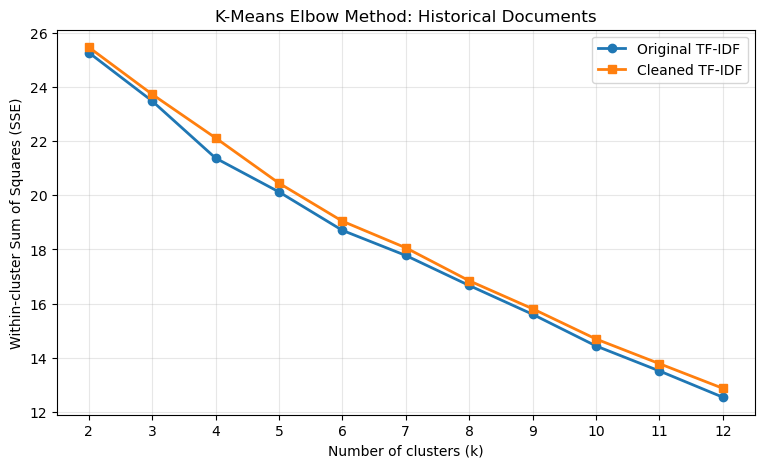

In [38]:
import matplotlib.pyplot as plt

# Create the figure
plt.figure(figsize=(9, 5))

# Plot inertia for the original TF-IDF representation
plt.plot(
    experiments_df["k"],
    experiments_df["inertia"],
    marker="o",
    linewidth=2,
    label="Original TF-IDF"
)

# Plot inertia for the cleaned-vocabulary representation
plt.plot(
    clean_experiments_df["k"],
    clean_experiments_df["inertia"],
    marker="s",
    linewidth=2,
    label="Cleaned TF-IDF"
)

# Add descriptive labels
plt.title("K-Means Elbow Method: Historical Documents")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster Sum of Squares (SSE)")
plt.xticks(range(2, 13))
plt.legend()
plt.grid(alpha=0.3)


plt.show()

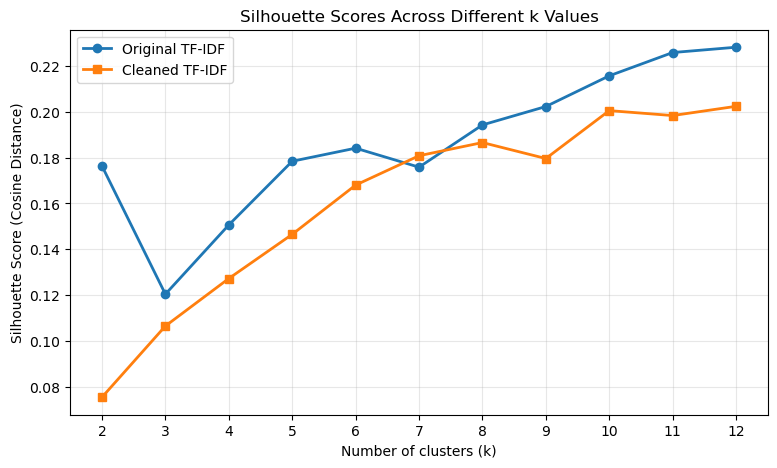

In [40]:
# Create the figure
plt.figure(figsize=(9, 5))

# Plot original TF-IDF silhouette scores
plt.plot(
    comparison_df["k"],
    comparison_df["silhouette_original"],
    marker="o",
    linewidth=2,
    label="Original TF-IDF"
)

# Plot cleaned TF-IDF silhouette scores
plt.plot(
    comparison_df["k"],
    comparison_df["silhouette_cleaned"],
    marker="s",
    linewidth=2,
    label="Cleaned TF-IDF"
)

# Add labels and formatting
plt.title("Silhouette Scores Across Different k Values")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score (Cosine Distance)")
plt.xticks(range(2, 13))
plt.legend()
plt.grid(alpha=0.3)


plt.show()

### Dimensionality Reduction

In [41]:
from sklearn.decomposition import TruncatedSVD

# Create a model that reduces our document vectors to 2 dimensions
svd = TruncatedSVD(
    n_components=2,
    random_state=42
)

# Project the original TF-IDF vectors into 2D
X_2d = svd.fit_transform(X_tfidf)

# Inspect the resulting matrix
print("Original dimensions:", X_tfidf.shape)
print("Reduced dimensions:", X_2d.shape)

# Check how much variance is retained in the 2D projection
print(
    "Explained variance:",
    round(svd.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Original dimensions: (33, 23955)
Reduced dimensions: (33, 2)
Explained variance: 11.49 %


### Plotting the six clusters